In [1]:
import numpy as np
import pandas as pd
from sklearn.svm import SVC
from tqdm import tqdm

In [11]:
import joblib
X_train = joblib.load(r'D:\City Lectures\Neural Computing\CW NECO\TEXT\X_train_prob.pkl')

y_train = joblib.load(r'D:\City Lectures\Neural Computing\CW NECO\TEXT\y_train_enc.pkl')

X_test = joblib.load(r'D:\City Lectures\Neural Computing\CW NECO\TEXT\X_test_prob.pkl')

y_test = joblib.load(r'D:\City Lectures\Neural Computing\CW NECO\TEXT\y_test_enc.pkl')


In [12]:
from sklearn.model_selection import train_test_split
X_test, X_val, y_test, y_val = train_test_split(
    X_test,
    y_test,
    test_size=0.50,
    stratify=y_test,
    random_state=42
)

In [ ]:
from sklearn.metrics import jaccard_score, make_scorer, f1_score
jaccard_macro_scorer = make_scorer(jaccard_score, average='macro')
scorer = make_scorer(f1_score, average='weighted')

0.44957735637377594

#### SVM

In [13]:
from sklearn import svm

In [ ]:
model = svm.SVC(kernel='linear',random_state=42)
model.fit(X_train, y_train)

#45 classifiers for 10 classes

,C,1.0
,kernel,'linear'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [18]:
y_pred=model.predict(X_val)

In [19]:
score = jaccard_score(y_pred, y_val, average='macro')
score

0.44957735637377594

In [ ]:
param_grid_svm = {
    'kernel': ['rbf'],
    'C': [0.01, 0.1, 1],
    # 'gamma': ['scale', 'auto'],
    'class_weight': ['balanced'],
    'decision_function_shape': ['ovr'],
    'max_iter': [5000]
}


In [25]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

In [26]:
grid_search_svm = GridSearchCV(
    estimator=svm.SVC(random_state=42),
    param_grid=param_grid_svm, scoring=jaccard_macro_scorer,cv=5,return_train_score=True,verbose=3,
    n_jobs=-1)
grid_search_svm.fit(X_train, y_train)

Fitting 5 folds for each of 16 candidates, totalling 80 fits


,estimator,SVC(random_state=42)
,param_grid,"{'C': [0.01, 0.1, ...], 'class_weight': ['balanced'], 'decision_function_shape': ['ovr'], 'gamma': ['scale', 'auto', ...], ...}"
,scoring,make_scorer(j...average=macro)
,n_jobs,-1
,refit,True
,cv,5
,verbose,3
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,True
,C,5


In [27]:
grid_search_svm.best_params_

{'C': 5,
 'class_weight': 'balanced',
 'decision_function_shape': 'ovr',
 'gamma': 'scale',
 'kernel': 'rbf',
 'max_iter': 5000}

In [28]:
results = pd.DataFrame(grid_search_svm.cv_results_)
results

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_C,param_class_weight,param_decision_function_shape,param_gamma,param_kernel,param_max_iter,...,mean_test_score,std_test_score,rank_test_score,split0_train_score,split1_train_score,split2_train_score,split3_train_score,split4_train_score,mean_train_score,std_train_score
0,231.424731,7.440606,20.603532,0.574300,0.01,balanced,ovr,scale,rbf,5000,...,0.199211,0.009068,6,0.194353,0.198662,0.200527,0.208136,0.201490,0.200634,0.004480
1,290.367539,8.154437,22.586150,1.234159,0.01,balanced,ovr,auto,rbf,5000,...,0.003545,0.001534,12,0.002273,0.002273,0.002273,0.005481,0.005481,0.003556,0.001572
2,289.650724,4.714204,22.389273,0.973225,0.01,balanced,ovr,0.001,rbf,5000,...,0.003545,0.001534,12,0.002273,0.002273,0.002273,0.005481,0.005481,0.003556,0.001572
3,275.341737,7.036755,22.958515,1.059668,0.01,balanced,ovr,0.01,rbf,5000,...,0.003545,0.001534,12,0.002273,0.002273,0.002273,0.005481,0.005481,0.003556,0.001572
4,112.608005,5.045584,16.035877,0.843254,0.10,balanced,ovr,scale,rbf,5000,...,0.464514,0.029040,3,0.478464,0.457557,0.464084,0.471993,0.470309,0.468481,0.007128
5,269.589073,3.574695,23.548305,0.808445,0.10,balanced,ovr,auto,rbf,5000,...,0.003117,0.000031,15,0.003113,0.003113,0.003113,0.003113,0.003132,0.003117,0.000008
6,267.596367,4.171061,23.385201,0.855821,0.10,balanced,ovr,0.001,rbf,5000,...,0.003117,0.000031,15,0.003113,0.003113,0.003113,0.003113,0.003132,0.003117,0.000008
7,263.261428,4.265327,22.646788,0.594445,0.10,balanced,ovr,0.01,rbf,5000,...,0.056993,0.001915,11,0.056215,0.056865,0.057120,0.057097,0.057796,0.057019,0.000508
8,61.438263,3.188363,11.066846,0.645523,1.00,balanced,ovr,scale,rbf,5000,...,0.581422,0.017945,2,0.616819,0.614340,0.620615,0.613638,0.622227,0.617528,0.003388
9,277.126554,4.306619,22.376955,1.389576,1.00,balanced,ovr,auto,rbf,5000,...,0.067329,0.002241,9,0.066078,0.065921,0.067856,0.067918,0.069056,0.067366,0.001196


In [32]:
score_comparison = results[[
    'param_C',
    'param_gamma',
    'mean_train_score',
    'mean_test_score',    
]]

# Sort by the test score to see the best performers
print(score_comparison.sort_values(by='mean_test_score', ascending=False))

    param_C param_gamma  mean_train_score  mean_test_score
12     5.00       scale          0.700890         0.647466
8      1.00       scale          0.617528         0.581422
4      0.10       scale          0.468481         0.464514
15     5.00        0.01          0.422533         0.421588
11     1.00        0.01          0.236765         0.236860
0      0.01       scale          0.200634         0.199211
14     5.00       0.001          0.098918         0.099122
10     1.00       0.001          0.086133         0.086104
9      1.00        auto          0.067366         0.067329
13     5.00        auto          0.065003         0.064690
7      0.10        0.01          0.057019         0.056993
1      0.01        auto          0.003556         0.003545
2      0.01       0.001          0.003556         0.003545
3      0.01        0.01          0.003556         0.003545
5      0.10        auto          0.003117         0.003117
6      0.10       0.001          0.003117         0.0031

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

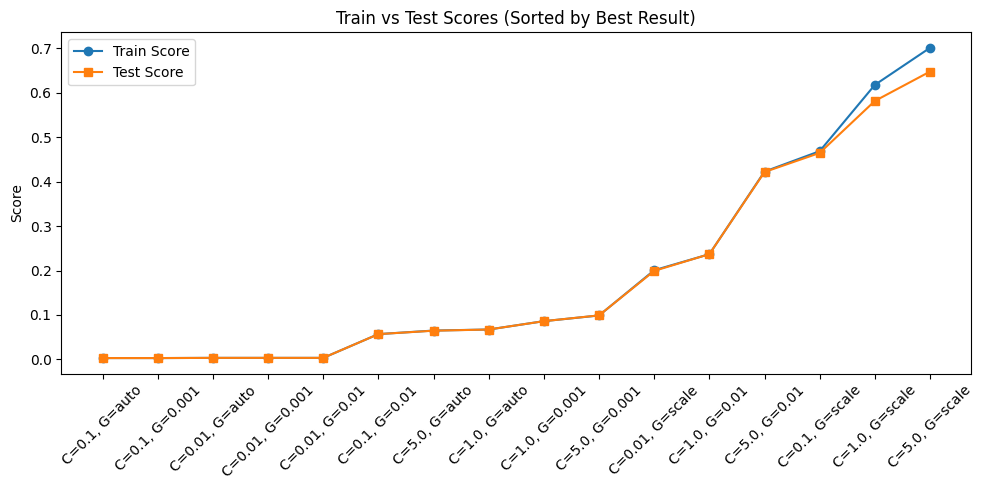

In [37]:
df_sorted = score_comparison.sort_values('mean_test_score', ascending=True).reset_index()
plt.figure(figsize=(10, 5))
plt.plot(df_sorted.index, df_sorted['mean_train_score'], label='Train Score', marker='o')
plt.plot(df_sorted.index, df_sorted['mean_test_score'], label='Test Score', marker='s')
plt.xticks(df_sorted.index, [f"C={c}, G={g}" for c, g in zip(df_sorted['param_C'], df_sorted['param_gamma'])], rotation=45)
plt.ylabel('Score')
plt.legend()
plt.title('Train vs Test Scores (Sorted by Best Result)')
plt.tight_layout()
plt.show()